	查看匹配条件，比较 Morgan 半径 2 和 3

In [1]:
import pandas as pd

component_columns = ["Aryl halide", "Ligand", "Base", "Additive"]

df = pd.read_excel(
    "data/raw/Dreher_and_Doyle_input_data.xlsx",
    sheet_name="FullCV_01",
    engine="openpyxl",
)

splits = pd.read_csv(
    "data/splits/split_manifest.csv",
    index_col="source_row_index",
)

test_predictions = pd.read_csv(
    "reports/morgan_random_forest/additive_test_predictions.csv",
    index_col="source_row_index",
)

assert df.index.equals(splits.index)
assert df[component_columns].equals(splits[component_columns])

training_data = df.loc[splits["additive_split"].eq("train")]
case_id = 2293
case = test_predictions.loc[case_id]

print("Case source row:", case_id)
print(f"Observed yield: {case['Output']:.2f}%")
print(f"Predicted yield: {case['predicted_yield']:.2f}%")

Case source row: 2293
Observed yield: 86.42%
Predicted yield: 42.23%


In [2]:
fixed_roles = ["Aryl halide", "Ligand", "Base"]

matching_mask = training_data[fixed_roles].eq(
    case[fixed_roles], axis="columns"
).all(axis=1)

matched_reactions = training_data.loc[matching_mask].copy()
matched_reactions.index.name = "source_row_index"

matched_reactions = matched_reactions.sort_values(
    "Output", ascending=False
)

print("Matched training reactions:", len(matched_reactions))
print("Held-out additive:", case["Additive"])

display(matched_reactions[["Additive", "Output"]])

Matched training reactions: 21
Held-out additive: C1(C2=CC=CC=C2)=CC=NO1


,Additive,Output
source_row_index,,
406,C1(C2=CC=CC=C2)=NOC=C1,95.128978
3561,CC1=CC(C(OCC)=O)=NO1,91.528623
771,CCOC(C1=NOC=C1)=O,89.974162
570,CC1=NOC(C(OCC)=O)=C1,86.535417
2712,CC1=NOC=C1,86.089809
1190,CC1=CC(C)=NO1,83.803868
1734,C1(N(CC2=CC=CC=C2)CC3=CC=CC=C3)=NOC=C1,80.065243
177,CC1=CC=NO1,79.687611
1452,CC1=NOC(C2=CC=CC=C2)=C1,73.813953


Case source row: 2293
Observed yield: 86.42%
Predicted yield: 42.23%


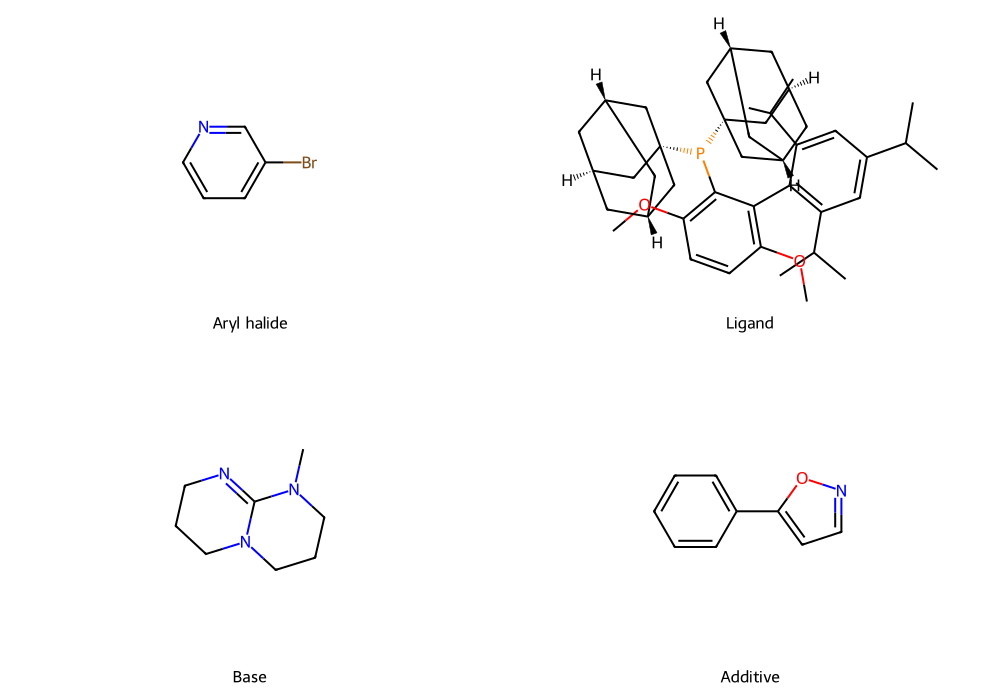

In [3]:
from rdkit import Chem
from rdkit.Chem import Draw

roles = ["Aryl halide", "Ligand", "Base", "Additive"]
molecules = []

for role in roles:
    molecule = Chem.MolFromSmiles(case[role])
    if molecule is None:
        raise ValueError(f"Invalid SMILES for {role}: {case[role]}")
    molecules.append(molecule)

print(f"Case source row: {case_id}")
print(f"Observed yield: {case['Output']:.2f}%")
print(f"Predicted yield: {case['predicted_yield']:.2f}%")

display(
    Draw.MolsToGridImage(
        molecules,
        legends=roles,
        molsPerRow=2,
        subImgSize=(500, 350),
        useSVG=True,
    )
)

In [4]:
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048,
    includeChirality=True,
)

target_fingerprint = generator.GetFingerprint(
    Chem.MolFromSmiles(case["Additive"])
)

similarity_table = matched_reactions[["Additive", "Output"]].copy()
similarities = []

for smiles in similarity_table["Additive"]:
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    fingerprint = generator.GetFingerprint(molecule)
    similarities.append(
        DataStructs.TanimotoSimilarity(target_fingerprint, fingerprint)
    )

similarity_table["similarity"] = similarities
similarity_table = similarity_table.sort_values(
    "similarity", ascending=False
)

print("Similarity table ready:", len(similarity_table), "reactions")

Similarity table ready: 21 reactions


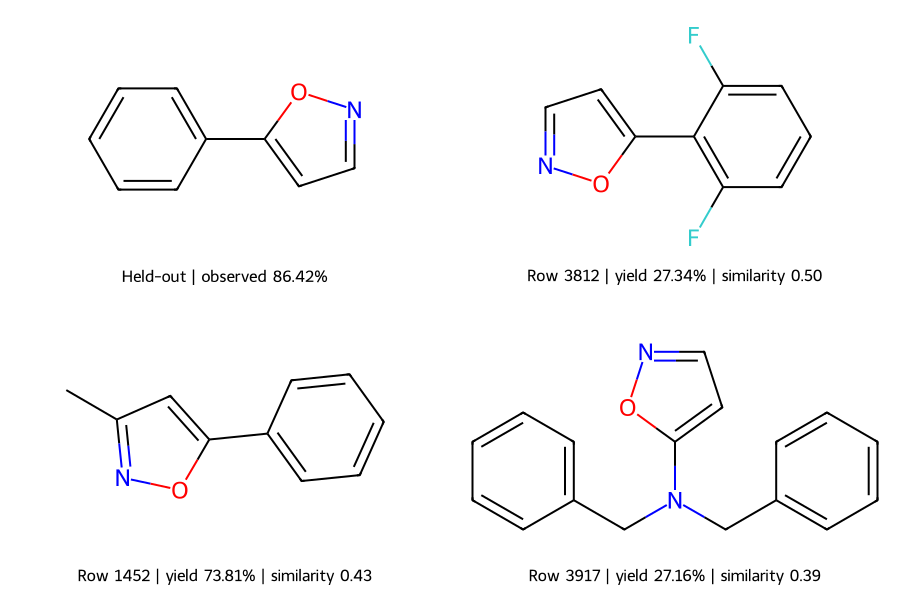

In [5]:
comparison_molecules = [Chem.MolFromSmiles(case["Additive"])]
comparison_labels = [
    f"Held-out | observed {case['Output']:.2f}%"
]

for row_id, row in similarity_table.head(3).iterrows():
    comparison_molecules.append(Chem.MolFromSmiles(row["Additive"]))
    comparison_labels.append(
        f"Row {row_id} | yield {row['Output']:.2f}%"
        f" | similarity {row['similarity']:.2f}"
    )

display(
    Draw.MolsToGridImage(
        comparison_molecules,
        legends=comparison_labels,
        molsPerRow=2,
        subImgSize=(450, 300),
        useSVG=True,
    )
)

### 案例 2293 的诊断记录

固定芳基卤化物、配体和碱后，21 种训练添加剂对应的实测产率
范围为 14.39%–95.13%。留出添加剂的实测产率为 86.42%，
模型预测为 42.23%。

已查看分子结构和结构相似度，目前尚未找到有充分依据的化学解释。
保留该案例，后续结合更多添加剂的验证结果分析。

In [6]:
import json
import joblib
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_val_score

with open(
    "reports/morgan_random_forest/additive_config.json",
    encoding="utf-8",
) as file:
    model_config = json.load(file)

reference_model = joblib.load(
    "reports/morgan_random_forest/additive_model.joblib"
)

roles = model_config["roles"]
settings = model_config["fingerprint"]

grouped_cv = GroupKFold(n_splits=3)
cv_splits = list(grouped_cv.split(
    training_data,
    training_data["Output"],
    groups=training_data["Additive"],
))

print("Training records:", len(training_data))
print("Training additives:", training_data["Additive"].nunique())
print("Validation folds:", len(cv_splits))

Training records: 3775
Training additives: 21
Validation folds: 3


In [7]:
radius_results = []

unique_smiles = pd.unique(
    training_data[roles].to_numpy().ravel()
)

for radius in [2, 3]:
    print(f"Evaluating Morgan radius {radius}...")

    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=settings["fpSize"],
        includeChirality=settings["includeChirality"],
    )

    fingerprint_arrays = {}

    for smiles in unique_smiles:
        molecule = Chem.MolFromSmiles(smiles)
        if molecule is None:
            raise ValueError(f"Invalid SMILES: {smiles}")

        fingerprint_arrays[smiles] = np.array(
            list(generator.GetFingerprint(molecule)),
            dtype=np.uint8,
        )

    blocks = [
        np.stack([
            fingerprint_arrays[smiles]
            for smiles in training_data[role]
        ])
        for role in roles
    ]
    features = np.concatenate(blocks, axis=1)

    fold_mae = -cross_val_score(
        clone(reference_model),
        features,
        training_data["Output"],
        cv=cv_splits,
        scoring="neg_mean_absolute_error",
        n_jobs=1,
    )

    radius_results.append({
        "radius": radius,
        "fold_1_mae": fold_mae[0],
        "fold_2_mae": fold_mae[1],
        "fold_3_mae": fold_mae[2],
        "mean_mae": fold_mae.mean(),
        "std_mae": fold_mae.std(),
    })

radius_comparison = pd.DataFrame(radius_results)
display(radius_comparison.round(3))

Evaluating Morgan radius 2...
Evaluating Morgan radius 3...


,radius,fold_1_mae,fold_2_mae,fold_3_mae,mean_mae,std_mae
0,2,9.179,8.804,11.966,9.983,1.410
1,3,9.600,9.012,11.971,10.194,1.279


In [8]:
from pathlib import Path

improvement_dir = Path("reports/improvement")
improvement_dir.mkdir(parents=True, exist_ok=True)

radius_comparison.to_csv(
    improvement_dir / "morgan_radius_comparison.csv",
    index=False,
)
similarity_table.to_csv(
    improvement_dir / "case_2293_matched_additives.csv"
)

experiment_config = {
    "reference_model": "reports/morgan_random_forest/additive_model.joblib",
    "split_manifest": "data/splits/split_manifest.csv",
    "radii": [2, 3],
    "fpSize": settings["fpSize"],
    "includeChirality": settings["includeChirality"],
    "role_order": roles,
    "cv": "GroupKFold",
    "n_splits": 3,
    "group_column": "Additive",
    "model_parameters": reference_model.get_params(),
    "selected_radius": 2,
}

with (improvement_dir / "radius_experiment_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(experiment_config, file, indent=2)

print("Saved radius comparison, matched cases, and experiment config.")

Saved radius comparison, matched cases, and experiment config.


### Morgan 半径对照实验

固定 Random Forest 参数、指纹长度、手性设置和三折添加剂分组，
比较 Morgan 半径 2 与半径 3。

半径 2 的平均验证 MAE 为 9.983 个百分点，半径 3 为 10.194。
半径 3 在三个折中的误差均略高，因此本轮继续使用半径 2。

这是对固定模型参数下两种指纹半径的比较。本轮未获得误差改善。
后续候选方向包括更多添加剂留出评估，以及可核验的 DFT 描述符。